# Exercise 2 — Binary Classification

Class 1 is split into two clusters on opposite sides of Class 0, so no straight
line separates the classes. The MLP is the from-scratch class in `mlp.py`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from mlp import MLP

%matplotlib inline

FIG_DIR = Path("..") / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
from sklearn.datasets import make_blobs
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(42)
COLORS = {0: "#1f77b4", 1: "#d62728"}

## A — Generate the data

train: (800, 2) | test: (200, 2)


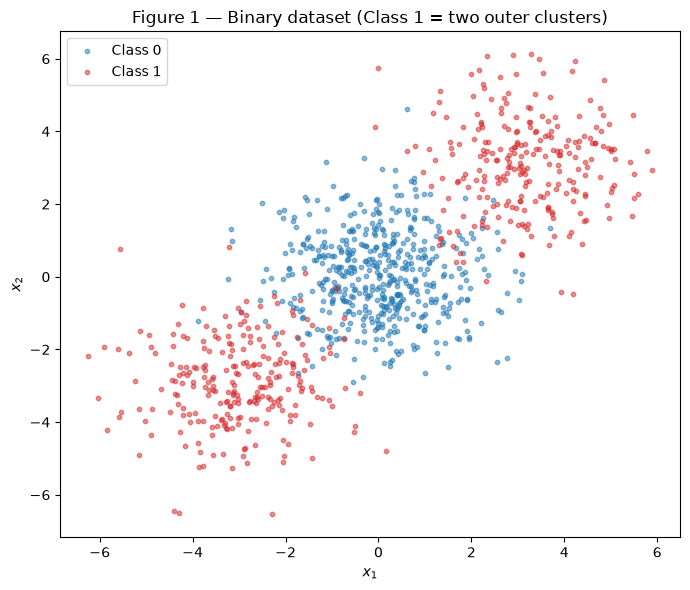

In [2]:
centers = np.array([[0., 0.], [3., 3.], [-3., -3.]])
X, c = make_blobs(n_samples=[500, 250, 250], centers=centers,
                  cluster_std=1.2, random_state=42)
y = (c > 0).astype(int)      # class 0: 1 cluster | class 1: 2 clusters
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("train:", X_train.shape, "| test:", X_test.shape)

fig, ax = plt.subplots(figsize=(7, 6))
for k in (0, 1):
    ax.scatter(X[y == k, 0], X[y == k, 1], s=10, alpha=0.5,
               color=COLORS[k], label=f"Class {k}")
ax.set_title("Figure 1 — Binary dataset (Class 1 = two outer clusters)")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "fig1_binary_data.png", dpi=150)
plt.show()

## B — Linear baseline (logistic regression)

In [3]:
baseline = LogisticRegression().fit(X_train, y_train)
baseline_acc = baseline.score(X_test, y_test)
print(f"Linear baseline test accuracy = {baseline_acc:.4f}")

Linear baseline test accuracy = 0.4750


## C — Train the MLP

Architecture `[2, 8, 1]`: 2 inputs, one hidden layer of 8 tanh units, one sigmoid
output; binary cross-entropy; full-batch gradient descent.

In [4]:
ARCH, LR, EPOCHS = [2, 8, 1], 0.5, 2000

model = MLP(ARCH, rng, output="sigmoid")
losses = model.fit(X_train, y_train, epochs=EPOCHS, lr=LR)
test_acc = model.accuracy(X_test, y_test)
print(f"architecture = {ARCH}, lr = {LR}, epochs = {EPOCHS}, params = {model.n_params()}")
print(f"final training loss = {losses[-1]:.4f}")
print(f"train accuracy = {model.accuracy(X_train, y_train):.4f}")
print(f"test accuracy  = {test_acc:.4f}")

architecture = [2, 8, 1], lr = 0.5, epochs = 2000, params = 33
final training loss = 0.1043
train accuracy = 0.9675
test accuracy  = 0.9150


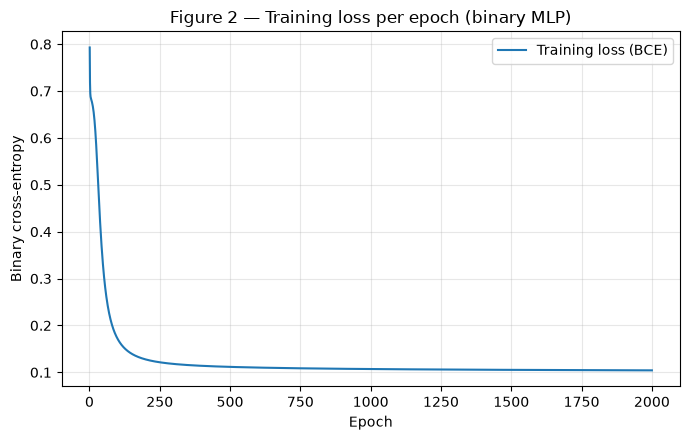

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(range(1, EPOCHS + 1), losses, color="#1f77b4", label="Training loss (BCE)")
ax.set_title("Figure 2 — Training loss per epoch (binary MLP)")
ax.set_xlabel("Epoch")
ax.set_ylabel("Binary cross-entropy")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "fig2_binary_loss.png", dpi=150)
plt.show()

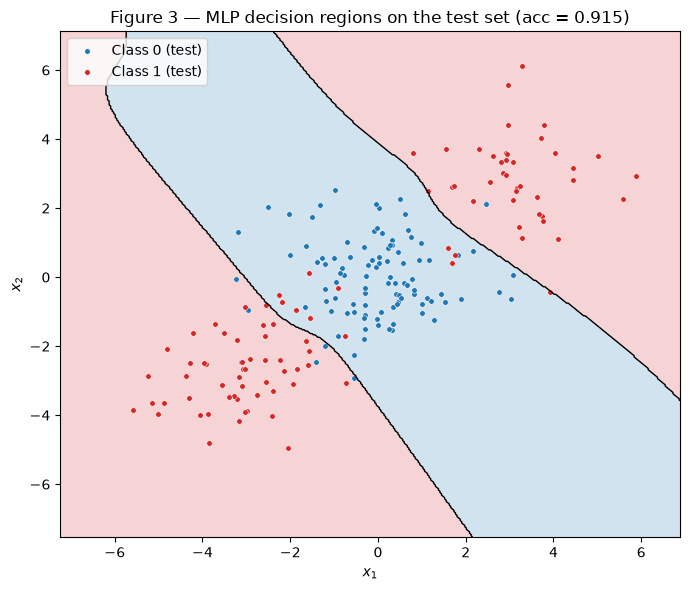

In [6]:
pad = 1.0
xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 400),
    np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 400))
grid_pred = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(7, 6))
ax.contourf(xx, yy, grid_pred, levels=[-0.5, 0.5, 1.5],
            colors=[COLORS[0], COLORS[1]], alpha=0.2)
ax.contour(xx, yy, grid_pred, levels=[0.5], colors="black", linewidths=1)
for k in (0, 1):
    ax.scatter(X_test[y_test == k, 0], X_test[y_test == k, 1], s=16,
               color=COLORS[k], edgecolors="white", linewidths=0.4,
               label=f"Class {k} (test)")
ax.set_title(f"Figure 3 — MLP decision regions on the test set (acc = {test_acc:.3f})")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "fig3_binary_boundary.png", dpi=150)
plt.show()